# КТ 1 — золотой набор и baseline без RAG

Набор построен скриптом `scripts/build_gold.py` (стадии generate → stylize → label → review → finalize),
baseline — скриптом `scripts/baseline_no_rag.py`. Методика описана в `README.md`; здесь — результат:
1. Состав набора и баланс разбиения validation/test.
2. Лексическое разнообразие формулировок.
3. Покрытие корпуса: источники, патчи, число релевантных документов на вопрос.
4. Ревью кандидатов: что отклонено и почему.
5. Baseline: как отвечает LLM без контекста — нужен ли RAG.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from gigarag import gold_coverage as coverage
from gigarag.answer_eval import VERDICTS, load_verdicts, summary_by_type, verdict_table
from gigarag.corpus import read_jsonl
from gigarag.gold import QUESTION_TYPES, load_gold

pd.set_option("display.max_colwidth", 160)
plt.rcParams["figure.dpi"] = 110

DATA = Path.cwd() / "data"
GOLD = Path.cwd() / "gold"
rows, CORPUS_SHA = read_jsonl(DATA / "corpus.jsonl")
sources = {r["doc_id"]: r["source"] for r in rows}
patches = {r["doc_id"]: r["patch"] for r in rows}
corpus_patches = {r["patch"] for r in rows if r["source"] == "patchnotes"}

items = load_gold(GOLD / "gold.jsonl")
questions = coverage.question_frame(items)
evidence = coverage.evidence_frame(items, sources, patches)
print(len(items), "вопросов; sha256 корпуса:", CORPUS_SHA[:16])

50 вопросов; sha256 корпуса: 76b0676b841020e9


## 1. Состав и разбиение

Разбиение стратифицировано по типу вопроса (`gigarag.gold.stratified_split`, seed 42): доля test ≈ 30%
внутри каждого типа.

In [2]:
coverage.split_balance(questions)

split,test,validation,test_%
qtype,,,
factual,4,11,26.7
composite,4,11,26.7
abstract,3,7,30.0
negative,3,7,30.0
ВСЕГО,14,36,28.0


Примеры — по одному вопросу каждого типа:

In [3]:
examples = [next(i for i in items if i.qtype == t) for t in QUESTION_TYPES]
pd.DataFrame([{"qid": i.qid, "qtype": i.qtype, "question": i.question, "answer": i.answer} for i in examples])

,qid,qtype,question,answer
0,q01,factual,"Я играю на Nature's Prophet и хочу лучше понимать его эффективность на ранней стадии после патча 7.35c. Подскажите, как изменился базовый урон этого героя с...",Базовый урон Nature's Prophet был уменьшен на 3 после патча 7.35c.
1,q16,composite,скажи пж как менялс рецпет и цена хевенс халберд в патчах 741 и 741ф,"В патче 7.41 рецепт Heaven's Halberd был изменён, его общая стоимость увеличилась до 3400 золота, а в патче 7.41f стоимость рецепта снизили, и итоговая стои..."
2,q31,abstract,в каком напрвлении были изменея карты в дота 2 в патче 7.40 и как это повлияло на иговые объекты и взимодействие с ними,"В патче 7.40 карта Dota 2 подверглась значительным изменениям: были переработаны ручьи на базах, введены защитные врата, изменено расположение лагерей нейтр..."
3,q41,negative,Какие изменения были внесены в героя Invoker в патче 7.29?,В корпусе нет информации для ответа.


## 2. Лексическое разнообразие

Часть вопросов переформулирована отдельным запросом к LLM: опечатки, разговорный стиль, сленговые
и сокращённые имена героев/предметов, короткий поисковый запрос, развёрнутый вопрос. Остальные
оставлены в нейтральной формулировке генератора.

In [4]:
by_style = questions.groupby("style").agg(questions=("qid", "size"), median_words=("words", "median"))
by_style["share_%"] = (by_style["questions"] / len(questions) * 100).round(1)
by_style.sort_values("questions", ascending=False)

,questions,median_words,share_%
style,,,
без изменений,15,17.0,30.0
typo,9,14.0,18.0
colloquial,8,26.0,16.0
short,7,7.0,14.0
long,6,55.0,12.0
name_variant,5,18.0,10.0


In [5]:
pd.crosstab(questions["style"], questions["split"])

split,test,validation
style,,
colloquial,3,5
long,2,4
name_variant,1,4
short,3,4
typo,1,8
без изменений,4,11


Как стилизация изменила формулировку (по одному примеру на стиль):

In [6]:
styled = {i.styles[0]: i for i in reversed(items) if i.styles}  # reversed: остаётся первый вопрос стиля
pd.DataFrame([{"style": s, "original": i.original_question, "styled": i.question} for s, i in styled.items()])

,style,original,styled
0,name_variant,Какой бонус к урону/лечению от Brain Sap теперь даёт талант 25 уровня у Bane после патча 7.37b?,Сколько теперь процентов бонуса к урону и отхилу с бреин сэпа даёт талант на 25 у бейна после патча 7.37b?
1,long,Какой базовый урон был у Nature's Prophet после патча 7.35c?,"Я играю на Nature's Prophet и хочу лучше понимать его эффективность на ранней стадии после патча 7.35c. Подскажите, как изменился базовый урон этого героя с..."
2,typo,Какой стал прирост силы у Tidehunter после патча 7.40b?,какой теперь прирсо рост силы у tidehunter апосле патча 7.40b
3,short,Какой бонус к радиусу взрыва у Unstable Concoction теперь даёт талант 10 уровня у Alchemist в патче 7.41?,Alchemist 7.41 талант радиус взрыва
4,colloquial,Какой предмет рекомендуется собирать на Рубика в лейте согласно гайду от Вани Золо?,"Чё по билду на Рубика в лейте, что Ваня Золо советует собирать, какой шмот юзать?"


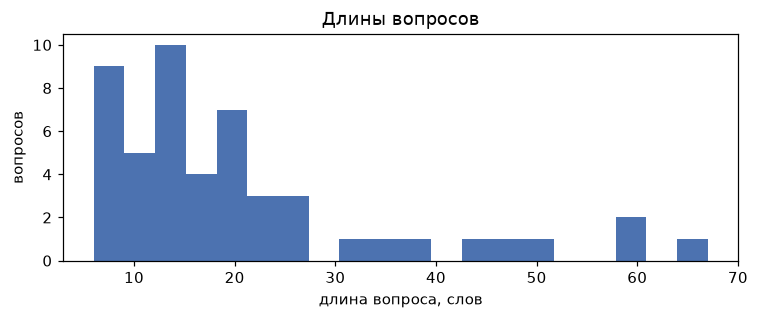

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(questions["words"], bins=20, color="#4C72B0")
ax.set_xlabel("длина вопроса, слов")
ax.set_ylabel("вопросов")
ax.set_title("Длины вопросов")
plt.tight_layout()
plt.show()

## 3. Покрытие корпуса

Оценка 2 — отрывок содержит ответ или его необходимую часть, 1 — по теме, но без ответа.
Ретривер в КТ 3 оценивается по документам с оценкой 2; оценка 1 нужна для NDCG.

In [8]:
questions.groupby("qtype")[["relevant_docs", "related_docs"]].describe().round(1).reindex(QUESTION_TYPES)

relevant_docs                                      related_docs  \
                  count mean  std  min  25%  50%   75%   max        count   
qtype                                                                       
factual            15.0  1.5  0.6  1.0  1.0  1.0   2.0   3.0         15.0   
composite          15.0  3.3  1.0  2.0  3.0  3.0   4.0   5.0         15.0   
abstract           10.0  9.3  4.4  2.0  6.5  9.0  13.0  15.0         10.0   
negative           10.0  0.0  0.0  0.0  0.0  0.0   0.0   0.0         10.0   

                                                    
           mean  std   min   25%   50%   75%   max  
qtype                                               
factual     8.3  3.1   4.0   6.0   7.0  11.0  13.0  
composite  11.6  7.7   1.0   5.5  11.0  18.0  24.0  
abstract   21.0  7.9  12.0  14.2  19.5  27.0  34.0  
negative    7.4  5.3   0.0   3.5   6.5  11.2  15.0

Из каких источников берутся ответы — доля вопросов типа (в %), у которых среди документов с ответом
есть документ источника:

In [9]:
coverage.source_coverage(evidence, questions)

source,dota2ru_article,dota2ru_comment,patchnotes,tg_Dota2,tg_gabenews
qtype,,,,,
factual,46.7,6.7,73.3,6.7,20.0
composite,66.7,33.3,100.0,33.3,0.0
abstract,30.0,20.0,40.0,90.0,40.0
negative,0.0,0.0,0.0,0.0,0.0


In [10]:
questions["answer_sources"] = coverage.sources_per_question(evidence, questions).to_numpy()
pd.crosstab(questions["qtype"], questions["answer_sources"]).reindex(QUESTION_TYPES)

answer_sources,0,1,2,3,4
qtype,,,,,
factual,0,8,6,1,0
composite,0,2,7,5,1
abstract,0,0,8,2,0
negative,10,0,0,0,0


Какие патчи покрыты: число вопросов, ответ на которые опирается на документ патча (патчноут, статью
dota2.ru или комментарий к ней). Посты Telegram к патчу не привязаны и здесь не учитываются.

патчей в корпусе: 36 покрыто хотя бы одним вопросом: 24


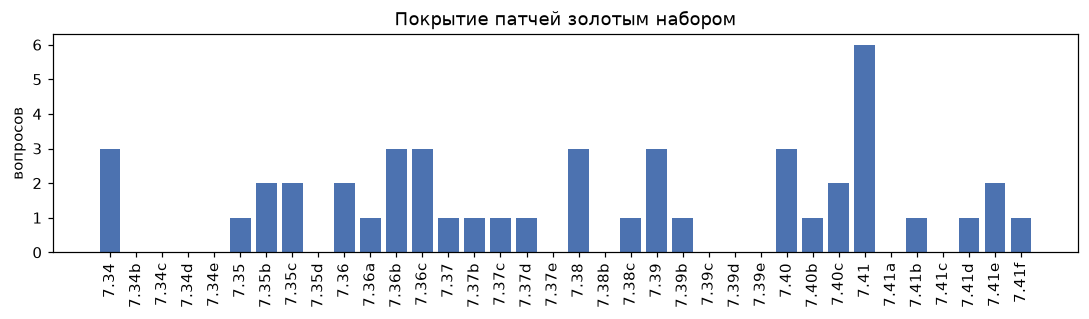

In [11]:
by_patch = coverage.patch_coverage(evidence, corpus_patches)
print("патчей в корпусе:", len(by_patch), "покрыто хотя бы одним вопросом:", (by_patch["questions"] > 0).sum())
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(by_patch.index, by_patch["questions"], color="#4C72B0")
ax.set_ylabel("вопросов")
ax.set_title("Покрытие патчей золотым набором")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

## 4. Ревью кандидатов

Каждый кандидат прошёл автоматические проверки (цитаты генератора есть в документе, судья подтвердил
затравку, нет дублей) и ручное ревью: `accept` — в набор, `reserve` — годен, но сверх квоты типа,
`reject` — отклонён.

In [12]:
records = {r["cid"]: r for r in map(json.loads, (DATA / "gold" / "labeled.jsonl").read_text(encoding="utf-8")
                                    .splitlines())}
review = coverage.review_frame(json.loads((GOLD / "review.json").read_text(encoding="utf-8")), records)
pd.crosstab(review["qtype"], review["decision"], margins=True, margins_name="ВСЕГО")

decision,accept,reject,reserve,ВСЕГО
qtype,,,,
abstract,10,4,0,14
composite,15,6,1,22
factual,15,2,5,22
negative,10,0,6,16
ВСЕГО,50,12,12,74


In [13]:
review.loc[review["decision"] == "reject", ["cid", "qtype", "question", "reason"]]

,cid,qtype,question,reason
16,c016,factual,"На каком герое игрок совершил Rampage после байбека, согласно публикации?","отсылка к «публикации» вместо вопроса игрока и неоднозначность: Rampage на Muerta есть в нескольких постах разных лет, единственного ответа нет"
17,c017,factual,"Йо, в 7.39d кто сейчас топовые оффлейн-коры? Топ-3 имбы на тройку кто ща?","ответ взят из еженедельного мета-отчёта, цитата генератора не совпадает с текстом; разные отчёты одного патча дают разные списки — эталон неустойчив"
26,c026,composite,"Как изменялась эффективность способности Blood Rite у Bloodseeker в патчах 7.36b и 7.39d, и какие ещё изменения этого героя затронули восстановление здоровья?",цитата генератора не найдена в документе; значения Blood Rite в ответе не подтверждаются отрывками — риск галлюцинации в эталоне
30,c030,composite,"Какие изменения произошли с героем Primal Beast в патче 7.37e и как игроки используют новые игровые функции, чтобы играть против этого героя?",искусственная связка: пост о функции «Лаборатории» не связан с правкой Primal Beast
32,c032,composite,"Я интересуюсь, что именно изменилось в способностях героя Dawnbreaker с выходом патча 7.37d в Dota 2. Также хотелось бы понять, каким образом эти изменения ...",неестественный вопрос: связывает правку способности с фильтрами стороннего сайта статистики
36,c036,composite,Какие изменения произошли с Vengeful Spirit в патче 7.35c и какие новости связаны с этим героем в сообществе в 2024 году?,искусственная связка: правка героя и новость о будущей аркане — разные темы
37,c037,composite,что поменялось с яша в патче 7.35б и чё думают игроки по этому поводу,судья не подтвердил комментарий-затравку: часть ответа «что думают игроки» без опоры в разметке
42,c042,composite,Как изменения в таланте Windranger на 15 уровне в патче 7.34 соотносятся с изменением работы предмета Nullifier в контексте взаимодействия с невосприимчивос...,блок патчноута про таланты Windranger судья не подтвердил; вопрос запутан и смешивает две несвязанные правки
49,c049,abstract,"Какие основные настроения и тренды можно выделить в обсуждениях дотеров по балансу патчей доты с августа 2023 по октябрь 2026? Например, как люди реагируют ...","стилизация исказила вопрос: добавлены требования (мемы, конкретные герои и предметы), на которые эталонный ответ не отвечает"
50,c050,abstract,как игроки вобще воспринлип изменения в баллнсе в патчах дота2 за этот пеиод ощущяеся какой то прогресс и разннобразие или вцелом недоволтсво,вопрос ссылается на «этот период» без контекста — для реального пользователя бессмыслен


## 5. Baseline без RAG

Две модели отвечают на вопросы validation без контекста (t = 0). Системный промпт задаёт те же границы,
что будут у RAG-системы: баланс Dota 2 в патчах 7.34–7.41f, вне их и при незнании — ответ «Не знаю».
Отказ распознаётся детерминированно (`gigarag.patterns.is_abstention`): на негативном вопросе он верен,
на остальных — `abstained`. Прочие ответы судья `gpt-4.1` сравнивает с эталоном.
Балл: correct — 1, partial — 0,5. Ошибки двух видов считаются отдельно: `hallucinated` — неверный
содержательный ответ на вопрос, у которого ответ есть; `missed_abstention` — содержательный ответ
на негативный вопрос вместо отказа. Все вердикты судьи проверены вручную; исправления с причинами —
`gold/baseline_review.json`, в `rationale` такого ответа указан и исходный вердикт судьи.

In [14]:
verdicts = load_verdicts(GOLD / "baseline_no_rag.jsonl")
summary = summary_by_type(verdicts)
summary

n  correct  partial  incorrect  \
model                   qtype                                          
gpt-4.1-2025-04-14      abstract    7.0     14.3     42.9        0.0   
                        composite  11.0      0.0      0.0       90.9   
                        factual    11.0      9.1      0.0       63.6   
                        negative    7.0     85.7      0.0       14.3   
                        ВСЕГО      36.0     22.2      8.3       50.0   
gpt-4.1-mini-2025-04-14 abstract    7.0     14.3     42.9        0.0   
                        composite  11.0      0.0     18.2       81.8   
                        factual    11.0      0.0      0.0       72.7   
                        negative    7.0     85.7      0.0       14.3   
                        ВСЕГО      36.0     19.4     13.9       50.0   

                                   abstained  score_%  hallucinated_%  \
model                   qtype                                           
gpt-4.1-2025-04-14      abstract        42.9     35.7             0.0   
                        composite        9.1      0.0            90.9   
                        factual         27.3      9.1            63.6   
                        negative         0.0     85.7             0.0   
                        ВСЕГО           19.4     26.4            47.2   
gpt-4.1-mini-2025-04-14 abstract        42.9     35.7             0.0   
                        composite        0.0      9.1            81.8   
                        factual         27.3      0.0            72.7   
                        negative         0.0     85.7             0.0   
                        ВСЕГО           16.7     26.4            47.2   

                                   missed_abstention_%  
model                   qtype                           
gpt-4.1-2025-04-14      abstract                   0.0  
                        composite                  0.0  
                        factual                    0.0  
                        negative                  14.3  
                        ВСЕГО                      2.8  
gpt-4.1-mini-2025-04-14 abstract                   0.0  
                        composite                  0.0  
                        factual                    0.0  
                        negative                  14.3  
                        ВСЕГО                      2.8

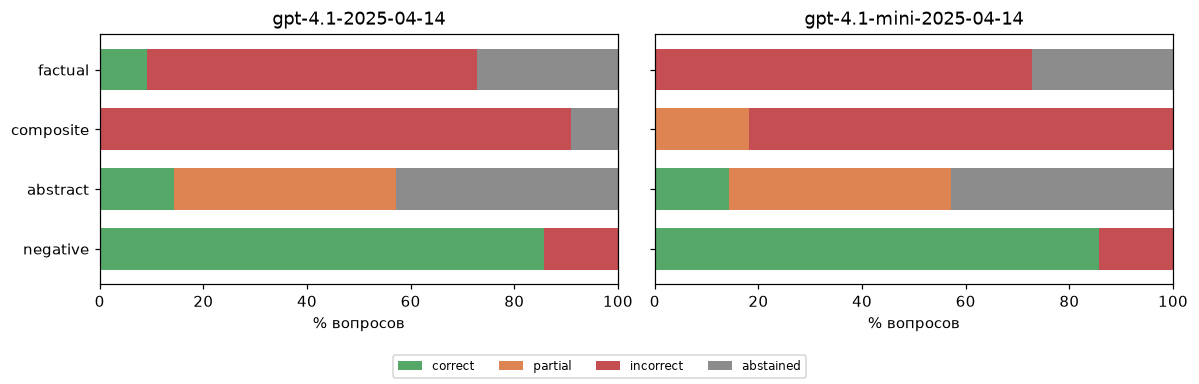

In [15]:
table = verdict_table(verdicts)
shares = (pd.crosstab([table["model"], table["qtype"]], table["verdict"], normalize="index")
          .reindex(columns=list(VERDICTS), fill_value=0) * 100)
colors = {"correct": "#55A868", "partial": "#DD8452", "incorrect": "#C44E52", "abstained": "#8C8C8C"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, model in zip(axes, shares.index.get_level_values("model").unique(), strict=True):
    part = shares.loc[model].reindex(QUESTION_TYPES)
    part.plot.barh(stacked=True, ax=ax, color=[colors[v] for v in VERDICTS], legend=False, width=0.7)
    ax.set_title(model)
    ax.set_xlabel("% вопросов")
    ax.invert_yaxis()
axes[0].set_ylabel("")
fig.legend(VERDICTS, loc="lower center", ncol=len(VERDICTS), fontsize=8)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

Ответы без контекста на негативные вопросы (в корпусе ответа нет) — проверка, умеет ли модель
признать незнание:

In [16]:
negative = table[table["qtype"] == "negative"]
negative[["qid", "model", "verdict", "answer"]].sort_values(["qid", "model"])

,qid,model,verdict,answer
65,q41,gpt-4.1-2025-04-14,correct,Не знаю. Я отвечаю только по патчам 7.34–7.41f.
29,q41,gpt-4.1-mini-2025-04-14,correct,"Не знаю. Патч 7.29 вышел до 7.34, поэтому изменения в нем не входят в мой диапазон знаний."
66,q42,gpt-4.1-2025-04-14,correct,Не знаю. Могу рассказать только про изменения в патчах 7.34–7.41f.
30,q42,gpt-4.1-mini-2025-04-14,incorrect,В патче 7.32 у Кристал Мейден убрали талант на реген маны. Теперь у неё нет такого таланта в дереве.
67,q43,gpt-4.1-2025-04-14,correct,Не знаю.
31,q43,gpt-4.1-mini-2025-04-14,correct,Не знаю. В патчах 7.34–7.41f изменений Impetus у Enchantress не было. Патч 7.29 — вне моего диапазона.
68,q44,gpt-4.1-2025-04-14,correct,Не знаю. На момент патча 7.41f информации о балансе Spirit Breaker в 7.42 нет.
32,q44,gpt-4.1-mini-2025-04-14,correct,Не знаю. Информации о патче 7.42 и изменениях для Spirit Breaker в нем пока нет.
69,q45,gpt-4.1-2025-04-14,correct,Не знаю.
33,q45,gpt-4.1-mini-2025-04-14,correct,"Не знаю, изменений для Войда в патче 7.42 пока не анонсировали."


## Выводы

**Состав.** 50 вопросов: 15 фактических, 15 составных, 10 абстрактных, 10 негативных. Разбиение
36 validation / 14 test (28% test), в каждом типе в test 27–30% вопросов.

**Лексическое разнообразие.** 70% вопросов переформулированы: опечатки — 18% (цель ~15%),
разговорный стиль — 16%, короткий запрос — 14% (медиана 7 слов), развёрнутый вопрос — 12%
(медиана 55 слов), сленговые имена — 10%. Все стили есть в обеих частях разбиения; опечатки и сленговые
имена попали в test по одному разу — для сравнения по стилям надёжнее только validation.

**Покрытие.** Число документов с ответом растёт с типом вопроса: в среднем 1,5 у фактических, 3,3 у
составных, 9,3 у абстрактных. Это задумано: составному вопросу нужно собрать ответ из нескольких
документов, абстрактному — из обсуждений. У 13 из 15 составных ответ лежит в 2–4 источниках,
у фактических — в 1–2: у 7 из 15 правка из патчноута продублирована в статье dota2.ru.
Патчноуты — основа фактических и составных вопросов (73% и 100%). Абстрактные вопросы опираются на
Telegram (90% @Dota2, 40% @gabenews) и комментарии — «грязная» часть корпуса тоже входит в набор.
Вопросы затрагивают 24 из 36 патчей окна корпуса; непокрытые 12 — мелкие буквенные хотфиксы
(7.34b–e, 7.35d, 7.37e, 7.38b, 7.39c–e, 7.41a, 7.41c). Сильнее всех покрыт крупный патч 7.41.

**Ревью.** Из 74 кандидатов отклонены 12. Причины: искусственная связка двух несвязанных тем
в составном вопросе (4), неподтверждённый или неустойчивый эталон (3), вопрос без контекста или
неоднозначный (3), стилизация исказила вопрос (2). Ещё 12 годных кандидатов — в резерве сверх квоты.

**Baseline без RAG.** Без контекста обе модели набирают 26,4% балла. На вопросах, у которых ответ
в корпусе есть, неверный содержательный ответ дают в 17 из 29 случаев (59%), отказываются — в 6–7.
Хуже всего фактические и составные вопросы (балл 0–9%, выдумки в 17 из 22): конкретные числа правок
по патчам модель не помнит и уверенно сочиняет. Абстрактные проходят частично (36%): общие тезисы
про «мету» модель знает из предобучения, но на трёх из семи она отказывается.
Границы корпуса в промпте работают: на негативных вопросах обе модели отказываются в 6 из 7 случаев,
включая патчи 7.29 и 7.32. Пропущенный отказ — по одному у каждой: mini ответила по памяти про 7.32,
полная модель описала несуществующего «Phantom Golem» как юнит Book of Shadows.
Судья без ручной проверки завышал оценки: 6 вердиктов partial/correct у ответов с выдуманными правками
исправлены на incorrect (`gold/baseline_review.json`). Большая модель не лучше малой.
Значит, RAG нужен в первую очередь ради точных фактов по версиям. Генератор для КТ 5 — gpt-4.1-mini:
качество без контекста то же, стоимость ниже.